# Olbrecht et al. 2021 — HGSOC
## 02 · Cell-state manifold → trajectory → root → pseudotime

Score the three embryonic modules, **check the biology before the geometry** (is this one axis,
and is the proliferation pocket a confound?), then fit the trajectory whose topology the data
support. Gast/pSom **co-vary** and both oppose Crest → a single non-branching axis → scFates
**`curve`** (not `tree`), rooted at the Gast/pSom-high, Crest-low developmental origin.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
# load processed manifold; confirm it is a single elongated cloud (not two blobs)
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, s, _ = np.linalg.svd(c, full_matrices=False)
print('whole malignant manifold:', adata.shape[0], 'cells')
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
adata

whole malignant manifold: 3936 cells
UMAP aspect ratio (major/minor std): 1.19


AnnData object with n_obs × n_vars = 3936 × 22675
    obs: 'sample', 'patient', 'cell_type', 'cell_subtype', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'sample_site', 'celltype', 'lobe', 'cycling'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'lobe', 'lobe_colors', 'log1p', 'neighbors', 'patient_colors', 'pca', 'sample_colors', 'source_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_lin'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [4]:
# score the three embryonic modules (union control pool) + graph-smooth for geography.
# smoothing is for reading GEOGRAPHY/topology here; the deliverable UMAPs in 03 show RAW scores.
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast', 'pSom', 'Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast', 'pSom', 'Crest']): adata.obs[lab+'_sm'] = S[:, j]
print('raw module means:', adata.obs[['Gast', 'pSom', 'Crest']].mean().round(3).to_dict())

Gast: 76/81 genes present
pSom: 91/98 genes present
Crest: 104/104 genes present
raw module means: {'Gast': 0.029, 'pSom': 0.077, 'Crest': -0.02}


In [5]:
# BIOLOGY BEFORE GEOMETRY: is the manifold one axis, and is the cycling pocket a confound?
# Kurten/Lin/Qian risk -> test that the module relationships survive removing cycling cells.
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S', 'G2/M', 'Intermediate'])
nc = ~adata.obs['cycling'].values
print('smoothed spatial correlations (whole | non-cycling %d cells):' % nc.sum())
for a, b in [('Gast_sm', 'pSom_sm'), ('Crest_sm', 'Gast_sm'), ('Crest_sm', 'pSom_sm')]:
    r  = np.corrcoef(adata.obs[a], adata.obs[b])[0, 1]
    rn = np.corrcoef(adata.obs[a].values[nc], adata.obs[b].values[nc])[0, 1]
    print(f'  {a} vs {b}: r = {r:+.2f} | non-cycling r = {rn:+.2f}')
cyc = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
print('proliferation confound (Spearman module vs g2m_score):')
for m in ['Gast', 'pSom', 'Crest']:
    rho, _ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs g2m: rho = {rho:+.2f}')
# module gene-set overlap with Regev-Tirosh cell-cycle genes (are the modules cc-driven?)
cc = set('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8 HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANLN TUBB4B GTSE1 KIF20B HJURP CDCA3 CDC20 TTK CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 LBR CKAP5 CENPE CTCF NEK2 G2E3 GAS2L3 CBX5 CENPA'.split())
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    gs = set(feat[src]); print(f'  {lab} cell-cycle-gene overlap: {len(gs & cc)}/{len(gs)}')
print('-> Gast/pSom co-vary (stronger among non-cycling); both oppose Crest; pSom<->Crest anti-')
print('   correlation SURVIVES excluding cycling cells; module sets are cell-cycle-free.')
print('   the developmental axis is orthogonal to the cycling pocket -> keep the WHOLE manifold.')

smoothed spatial correlations (whole | non-cycling 3212 cells):
  Gast_sm vs pSom_sm: r = +0.44 | non-cycling r = +0.71
  Crest_sm vs Gast_sm: r = +0.06 | non-cycling r = -0.07
  Crest_sm vs pSom_sm: r = -0.68 | non-cycling r = -0.63
proliferation confound (Spearman module vs g2m_score):
  Gast vs g2m: rho = +0.02
  pSom vs g2m: rho = +0.18
  Crest vs g2m: rho = -0.14
  Gast cell-cycle-gene overlap: 0/81
  pSom cell-cycle-gene overlap: 2/98
  Crest cell-cycle-gene overlap: 0/104
-> Gast/pSom co-vary (stronger among non-cycling); both oppose Crest; pSom<->Crest anti-
   correlation SURVIVES excluding cycling cells; module sets are cell-cycle-free.
   the developmental axis is orthogonal to the cycling pocket -> keep the WHOLE manifold.


In [6]:
# fit a principal CURVE (non-branching topology) + fold + branching diagnostics.
# curve, not tree: Gast/pSom co-vary rather than diverge into competing arms. verify a
# Puram-style PPT tree finds NO stable branchpoint that a curve would miss.
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B > 0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a, b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B > 0).sum(0) == 1).sum()); forks = int(((B > 0).sum(0) >= 3).sum())
    return dmin/med, tips, forks
for Nodes in [15, 20, 30]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(adata, Nodes=Nodes, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(adata)
    print(f'curve Nodes={Nodes}: {tips} tips, {forks} forks | self-approach ratio = {sa:.2f} (>1 = fold-free)')
sa, tips, forks = fold_diag(adata)
assert forks == 0 and sa > 1, 'topology check failed (expected fold-free 2-tip curve)'
print('non-branching curve confirmed (stable 2 tips / 0 forks, fold-free across Nodes 15-30)')

curve Nodes=15: 2 tips, 0 forks | self-approach ratio = 2.95 (>1 = fold-free)
curve Nodes=20: 2 tips, 0 forks | self-approach ratio = 2.68 (>1 = fold-free)
curve Nodes=30: 2 tips, 0 forks | self-approach ratio = 2.25 (>1 = fold-free)
non-branching curve confirmed (stable 2 tips / 0 forks, fold-free across Nodes 15-30)


In [7]:
# root at the developmental origin: the Gast/pSom-high, Crest-low tip (Crest is LATE).
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B > 0).sum(0) == 1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(),
                adata.obs['Crest_sm'][m].mean(), adata.obs['cycling'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.3f} pSom={info[tp][1]:+.3f} Crest={info[tp][2]:+.3f} cyc={info[tp][3]:.2f}')
root = int(max(tps, key=lambda tp: info[tp][0] + info[tp][1] - info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm', 'pSom_sm', 'Crest_sm']:
    rho, p = spearmanr(t, adata.obs[sname]); print(f'  {sname}: rho = {rho:+.3f}  p = {p:.1e}')
print('pseudotime vs cycling (g2m):', round(spearmanr(t, cyc)[0], 2),
      '(mild co-variation carried as a caveat, not an axis artefact)')

tip 0: Gast=+0.035 pSom=+0.083 Crest=-0.028 cyc=0.11
tip 2: Gast=+0.028 pSom=+0.090 Crest=-0.023 cyc=0.63
derived root = tip 0 (Gast/pSom-high, Crest-low = developmental origin)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.329  p = 1.0e-99
  pSom_sm: rho = -0.064  p = 6.0e-05
  Crest_sm: rho = +0.401  p = 8.5e-152
pseudotime vs cycling (g2m): 0.29 (mild co-variation carried as a caveat, not an axis artefact)


milestones: {'0': 'Gast/pSom origin', '2': 'Crest terminus'}


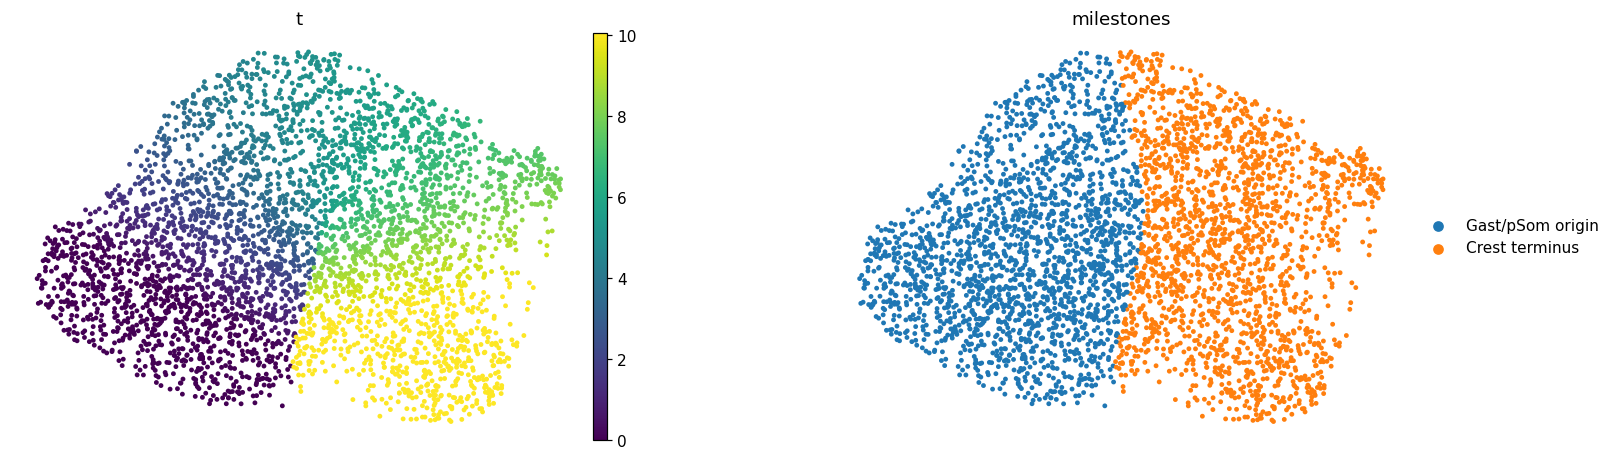

In [8]:
# visual inspection — pseudotime + milestones (root origin / terminus)
adata.obs['milestones'] = adata.obs['milestones'].astype('category')
ms = adata.obs['milestones'].cat.categories.tolist()
tmean = {m: adata.obs.loc[adata.obs['milestones'] == m, 't'].mean() for m in ms}
newnames = {m: ('Gast/pSom origin' if tmean[m] == min(tmean.values()) else 'Crest terminus') for m in ms}
scf.tl.rename_milestones(adata, new=newnames)
print('milestones:', newnames)
sc.pl.umap(adata, color=['t', 'milestones'], size=40, frameon=False, wspace=.3)

In [9]:
# orientation consistency: reuse the house X_umap_lin from 01, verify vs pseudotime
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:, 0], adata.obs['t'].values)[0, 1])
assert abs(r) > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
if r < 0:                                    # keep root/origin on the LEFT
    adata.obsm['X_umap_lin'][:, 0] = -adata.obsm['X_umap_lin'][:, 0]; r = -r
print(f'house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.84


In [10]:
# sanitize non-serializable ElPiGraph uns entry, then save manifold
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (3936, 22675)


saved manifold.pdf


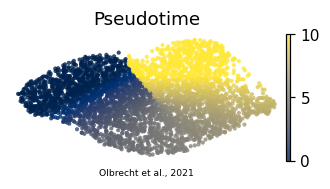

In [11]:
# deliverable: manifold.pdf — pseudotime on the house linear layout (3.5,1.5)
xl = adata.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Olbrecht et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')